In [ ]:
#CELL 1:(Import)
import os, sys, json, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True); os.makedirs("model", exist_ok=True)
R = {}   # results dictionary - everything printed here is stored for the report
print("Ready. RANDOM_STATE =", RANDOM_STATE)

In [ ]:
# CELL 2:(Load Dataset)
df = pd.read_csv("/content/sample_data/master_household_energy_dataset_with_hours final dataset.csv")


In [ ]:
#CELL 3:(Dataset Inspection)
print("Columns:", list(df.columns))
print("\nData types:"); print(df.dtypes.astype(str).value_counts())
print("\nThe file is several datasets stacked together:")
src = df.groupby("source_dataset").size().rename("rows"); display(src)
R["rows_per_source"] = {k: int(v) for k, v in src.items()}

In [ ]:
#CELL 4:(Data Quality Analysis)
miss = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(miss.head(12).to_frame("missing_%"))
R["overall_missing_pct"] = round(float(df.isna().mean().mean() * 100), 1)
R["empty_columns"] = [c for c in df.columns if df[c].isna().all()]
R["exact_duplicates"] = int(df.duplicated().sum())
R["near_duplicates_ignoring_id"] = int(df.duplicated(subset=[c for c in df.columns if c != "household_id"]).sum())
print("Overall missing: %.1f%%" % R["overall_missing_pct"])
print("100%% empty columns:", R["empty_columns"])
print("Exact duplicates:", R["exact_duplicates"], "| duplicates ignoring household_id:", R["near_duplicates_ignoring_id"])
print("\nMost missing cells are STRUCTURAL: each source dataset fills only its own columns.")

In [ ]:
#CELL 5:(Data Cleaning)
df["household_id"] = df["household_id"].astype("string")
for c in ["household_size", "num_rooms", "ave_monthly_income", "house_area_sqft"]:     # make sure these are numbers
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["season_std"] = df["season"].str.strip().str.lower().replace({"rainy": "monsoon", "fall": "autumn"})
hb = df["source_dataset"] == "Household energy bill data"
neg = {c: int((df.loc[hb, c] < 0).sum()) for c in ["household_size", "num_rooms", "ave_monthly_income"]}
for c in neg: df.loc[hb & (df[c] < 0), c] = np.nan
R["negative_values_fixed"] = neg
print("Negative values set to missing (small bill block):", neg)
df = df.drop_duplicates()          # exact duplicates only (there are none)
eb = df[df["source_dataset"] == "electricity_bill_dataset"].copy()   # modelling block
R["model_block_rows"] = int(len(eb))
print("Modelling block rows:", len(eb))

In [ ]:
#CELL 6:(Leakage Investigation)
calc = eb["monthly_total_kwh"] * eb["tariff_rate_inr_per_kwh"]
R["bill_identity_max_diff"] = float((calc - eb["monthly_bill_inr"]).abs().max())
R["monthlyhours_corr_with_kwh"] = float(eb["MonthlyHours"].corr(eb["monthly_total_kwh"]))
R["tariff_unique_per_city"] = int(eb.groupby("city")["tariff_rate_inr_per_kwh"].nunique().max())
R["motorpump_unique"] = int(eb["MotorPump"].nunique())
au = df[df["source_dataset"] == "appliance_usage_dataset"]
parts = ["ac_monthly_kwh","fridge_monthly_kwh","lights_monthly_kwh","fans_monthly_kwh","washing_machine_monthly_kwh","tv_monthly_kwh"]
R["appliance_sum_max_diff"] = float((au[parts].sum(axis=1) - au["monthly_total_kwh"]).abs().max())
R["appliance_block_rows"], R["appliance_block_households"] = int(len(au)), int(au["household_id"].nunique())
print("A) max |kWh x tariff - bill|        :", R["bill_identity_max_diff"], "-> bill is a formula of kWh")
print("B) tariff values per city (max)      :", R["tariff_unique_per_city"], "-> tariff depends only on city")
print("C) corr(MonthlyHours, kWh)           :", round(R["monthlyhours_corr_with_kwh"], 6), "-> copy of the target")
print("D) MotorPump unique values           :", R["motorpump_unique"], "-> constant, useless")
print("E) appliance block: total = sum of 6 appliance columns, max diff:", R["appliance_sum_max_diff"],
      "| rows:", R["appliance_block_rows"], "| households:", R["appliance_block_households"])
print("\nDecision: predict kWh. Exclude bill, MonthlyHours, tariff, MotorPump. Do not use the 560-row appliance block.")

In [ ]:
#CELL 7:(Modelling Table, Target and Features)

TARGET = "monthly_total_kwh"
CAT = ["city", "season"]
NUM = ["Fan", "Refrigerator", "AirConditioner", "Television", "Monitor"]
FEATURES = CAT + NUM
assert not set(FEATURES) & {"monthly_total_kwh","monthly_bill_inr","MonthlyHours","tariff_rate_inr_per_kwh","MotorPump"}
for c in NUM + [TARGET, "tariff_rate_inr_per_kwh"]:
    eb[c] = pd.to_numeric(eb[c], errors="coerce")
data = eb[FEATURES + [TARGET]].dropna(subset=[TARGET]).copy()
TARIFF = eb.groupby("city")["tariff_rate_inr_per_kwh"].first().to_dict()    # used only to convert kWh -> bill in the UI
R["modelling_rows"] = int(len(data)); R["missing_in_modelling_table"] = int(data.isna().sum().sum())
R["target_mean"], R["target_std"] = float(data[TARGET].mean()), float(data[TARGET].std())
R["target_min"], R["target_max"] = float(data[TARGET].min()), float(data[TARGET].max())
print(data.shape, "| missing:", R["missing_in_modelling_table"]); display(data.describe().round(1))


In [ ]:
#CELL 8:(Exploratory Data Analysis)
# Figure 4.1 - target distribution
plt.figure(figsize=(7, 4.2))
sns.histplot(data[TARGET], bins=40, kde=True, color="#2a6f97")
plt.title("Distribution of Monthly Electricity Consumption")
plt.xlabel("Monthly total consumption (kWh)"); plt.ylabel("Number of households")
plt.tight_layout(); plt.savefig("figures/fig_4_1_target_distribution.png", dpi=200); plt.show()
R["target_skew"] = float(data[TARGET].skew())
q1, q3 = data[TARGET].quantile([.25, .75]); iqr = q3 - q1
R["outliers_iqr"] = int(((data[TARGET] < q1 - 1.5*iqr) | (data[TARGET] > q3 + 1.5*iqr)).sum())
print("Skewness: %.3f | IQR outliers: %d" % (R["target_skew"], R["outliers_iqr"]))

# Figure 4.2 - correlation heatmap
corr = data[NUM + [TARGET]].corr()
R["corr_with_target"] = corr[TARGET].drop(TARGET).round(3).to_dict()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation Between Appliance Features and Monthly Consumption")
plt.tight_layout(); plt.savefig("figures/fig_4_2_correlation_heatmap.png", dpi=200); plt.show()
print(R["corr_with_target"])

# Figure 4.3 - appliance feature vs average consumption
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), NUM):
    g = data.groupby(f)[TARGET].mean()
    ax.plot(g.index, g.values, marker="o", color="#2a6f97")
    ax.set_title(f"Average Consumption by {f}", fontsize=11); ax.set_xlabel(f"{f} (dataset value)"); ax.set_ylabel("Mean monthly consumption (kWh)")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.savefig("figures/fig_4_3_appliance_vs_consumption.png", dpi=200); plt.show()

# Figure 4.4 - season boxplot and city means
order = ["Spring", "Summer", "Monsoon", "Autumn", "Winter"]
season_mean = data.groupby("season")[TARGET].mean().round(1); city_mean = data.groupby("city")[TARGET].mean().round(1).sort_values()
R["season_mean"], R["city_mean"] = season_mean.to_dict(), city_mean.to_dict()
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=data, x="season", y=TARGET, order=order, ax=ax[0], color="#8ecae6")
ax[0].set_title("Monthly Consumption by Season"); ax[0].set_xlabel("Season"); ax[0].set_ylabel("Monthly consumption (kWh)")
city_mean.plot.barh(ax=ax[1], color="#2a6f97")
ax[1].set_title("Average Monthly Consumption by City"); ax[1].set_xlabel("Mean monthly consumption (kWh)"); ax[1].set_ylabel("City")
plt.tight_layout(); plt.savefig("figures/fig_4_4_season_city.png", dpi=200); plt.show()
print(season_mean.to_dict()); print(city_mean.to_dict())

In [ ]:
#CELL 9:(Feature Selection and Train-Test Split 80:20)
X, y = data[FEATURES], data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
R["train_rows"], R["test_rows"] = int(len(X_train)), int(len(X_test))
print("Train:", len(X_train), "| Test:", len(X_test))

In [ ]:
#CELL 10:(Preprocessing Pipeline)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), NUM),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT),
])
print("Preprocessing pipeline defined (fitted inside each model pipeline, on training data only).")

leak_pre = ColumnTransformer([("num", StandardScaler(), NUM + ["MonthlyHours"]), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
Xl = eb[FEATURES + ["MonthlyHours"]]
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, eb[TARGET], test_size=0.20, random_state=RANDOM_STATE)
leak_pred = Pipeline([("p", leak_pre), ("m", LinearRegression())]).fit(Xl_tr, yl_tr).predict(Xl_te)
R["leaky_model_r2"] = float(r2_score(yl_te, leak_pred)); R["leaky_model_mae"] = float(mean_absolute_error(yl_te, leak_pred))
print("Linear Regression WITH leaky MonthlyHours: R2 = %.4f, MAE = %.4f kWh  <- artificially perfect" % (R["leaky_model_r2"], R["leaky_model_mae"]))


In [ ]:
#CELL 11:(Baseline Models, Advanced Models and Evaluation)
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=10, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
}
R["mean_predictor"] = metrics(y_test, np.full(len(y_test), y_train.mean()))
print("Reference (always predict the training mean):", {k: round(v, 3) for k, v in R["mean_predictor"].items()})

fitted, rows = {}, []
for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)]).fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"Model": name, **metrics(y_test, pipe.predict(X_test))})
    print(f"{name:<20} done")
results = pd.DataFrame(rows).round(4); display(results)


In [ ]:
#CELL 12:(Cross-Validation (5-fold on the training set))
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", m)])
    s = -cross_val_score(pipe, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
    cv_rows.append({"Model": name, "CV_RMSE_mean": s.mean(), "CV_RMSE_std": s.std()})
cv_df = pd.DataFrame(cv_rows).round(3); display(cv_df)

In [ ]:
#CELL 13:(Hyperparameter Tuning (Gradient Boosting) - baseline vs tuned)
param_dist = {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.05, 0.1],
              "model__max_depth": [2, 3, 4], "model__subsample": [0.7, 0.85, 1.0]}
search = RandomizedSearchCV(Pipeline([("prep", preprocessor), ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))]),
                            param_dist, n_iter=8, cv=3, scoring="neg_root_mean_squared_error",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
tuned = search.best_estimator_
R["tuned_gb_params"] = {k.replace("model__", ""): (float(v) if isinstance(v, float) else int(v)) for k, v in search.best_params_.items()}
R["tuned_gb_cv_rmse"] = float(-search.best_score_)
print("Best parameters:", R["tuned_gb_params"])
tuned_m = metrics(y_test, tuned.predict(X_test))
base_m = results.set_index("Model").loc["Gradient Boosting"].to_dict()
cmp = pd.DataFrame([{"Model": "Gradient Boosting (baseline)", **base_m}, {"Model": "Gradient Boosting (tuned)", **tuned_m}]).round(4)
display(cmp)
fitted["Gradient Boosting (tuned)"] = tuned
cv_t = -cross_val_score(tuned, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
cv_df = pd.concat([cv_df, pd.DataFrame([{"Model": "Gradient Boosting (tuned)", "CV_RMSE_mean": cv_t.mean(), "CV_RMSE_std": cv_t.std()}]).round(3)], ignore_index=True)
results = pd.concat([results, pd.DataFrame([{"Model": "Gradient Boosting (tuned)", **tuned_m}]).round(4)], ignore_index=True)

Best parameters: {'subsample': 0.85, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.03}


,Model,MAE,RMSE,R2
0,Gradient Boosting (baseline),71.0605,82.4806,0.5408
1,Gradient Boosting (tuned),71.0700,82.5301,0.5403


,Model,MAE,RMSE,R2,CV_RMSE_mean,CV_RMSE_std
0,Linear Regression,70.9307,82.3138,0.5427,81.881,0.255
1,Ridge Regression,70.9313,82.3143,0.5427,81.881,0.255
2,Decision Tree,72.5642,85.1983,0.5101,84.997,0.356
3,Random Forest,71.4911,83.2883,0.5318,82.855,0.118
4,Gradient Boosting,71.0605,82.4806,0.5408,82.191,0.255
5,Gradient Boosting (tuned),71.0700,82.5301,0.5403,82.201,0.239


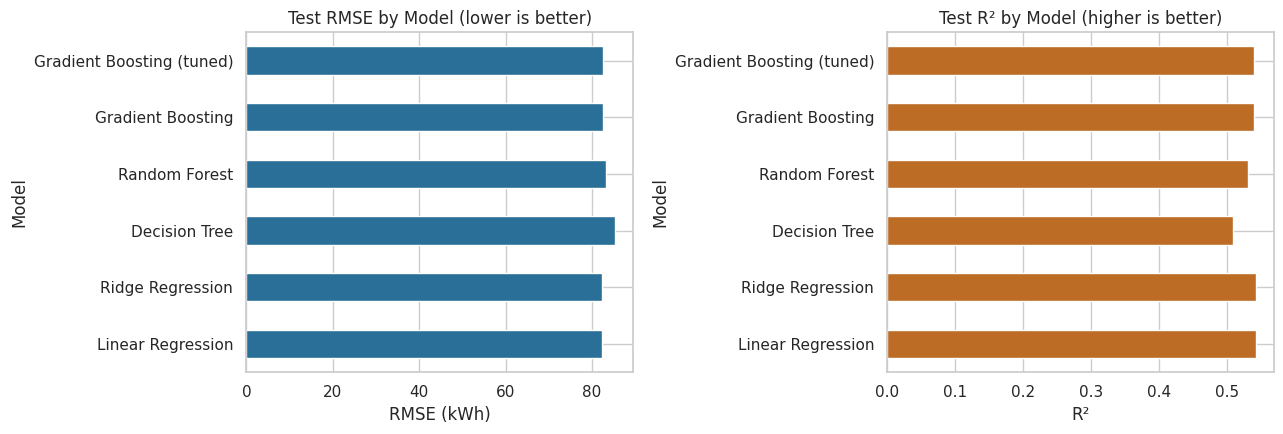

In [ ]:
#CELL 14:(Model Comparison)
table41 = results.merge(cv_df, on="Model"); table41.to_csv("outputs/table_4_1_model_comparison.csv", index=False); display(table41)
R["table_4_1"] = table41.to_dict(orient="records")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
table41.set_index("Model")["RMSE"].plot.barh(ax=ax[0], color="#2a6f97")
ax[0].set_title("Test RMSE by Model (lower is better)"); ax[0].set_xlabel("RMSE (kWh)"); ax[0].set_ylabel("Model")
table41.set_index("Model")["R2"].plot.barh(ax=ax[1], color="#bc6c25")
ax[1].set_title("Test R\u00b2 by Model (higher is better)"); ax[1].set_xlabel("R\u00b2"); ax[1].set_ylabel("Model")
plt.tight_layout(); plt.savefig("figures/fig_4_5_model_comparison.png", dpi=200); plt.show()

In [ ]:
#CELL 15:(Final Model Selection)
simplicity = ["Linear Regression", "Ridge Regression", "Decision Tree", "Gradient Boosting", "Gradient Boosting (tuned)", "Random Forest"]
best_cv = cv_df["CV_RMSE_mean"].min()
close = cv_df[cv_df["CV_RMSE_mean"] <= best_cv * 1.005]["Model"].tolist()
FINAL_NAME = sorted(close, key=simplicity.index)[0]
final_model = fitted[FINAL_NAME]
final_pred = final_model.predict(X_test)
final_m = metrics(y_test, final_pred)
R["final_model"] = FINAL_NAME; R["final_metrics"] = final_m; R["models_within_0.5pct_of_best_cv"] = close
print("Models within 0.5% of best CV RMSE:", close)
print("FINAL MODEL:", FINAL_NAME); print({k: round(v, 4) for k, v in final_m.items()})

Models within 0.5% of best CV RMSE: ['Linear Regression', 'Ridge Regression', 'Gradient Boosting', 'Gradient Boosting (tuned)']
FINAL MODEL: Linear Regression
{'MAE': 70.9307, 'RMSE': 82.3138, 'R2': 0.5427}


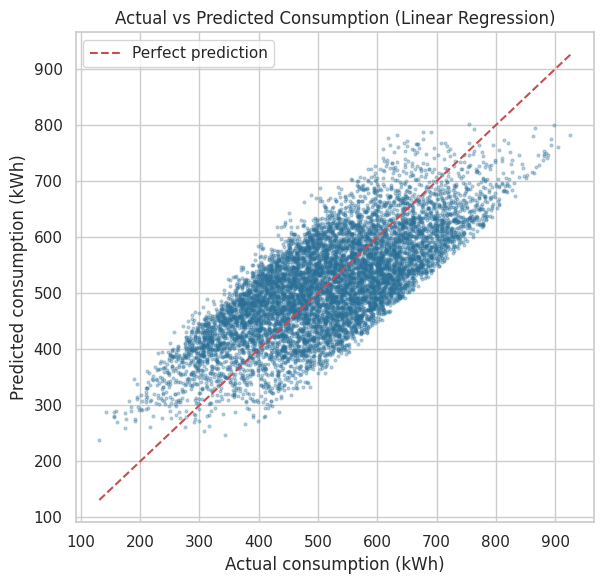

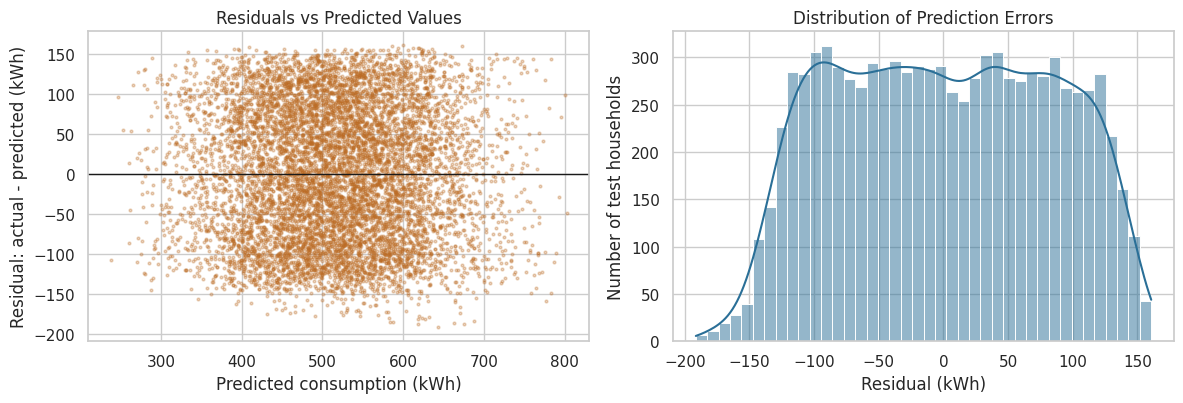

Residual mean 0.15, std 82.31 | within 50 kWh: 35.9% | within 100 kWh: 71.5%


In [ ]:
#CELL 16:(Actual vs Predicted and Residual Analysis)
resid = y_test.values - final_pred
R["residual_mean"], R["residual_std"] = float(resid.mean()), float(resid.std())
R["within_50_kwh_pct"] = float((np.abs(resid) <= 50).mean() * 100); R["within_100_kwh_pct"] = float((np.abs(resid) <= 100).mean() * 100)
plt.figure(figsize=(6.2, 6))
plt.scatter(y_test, final_pred, s=4, alpha=0.3, color="#2a6f97")
lims = [min(y_test.min(), final_pred.min()), max(y_test.max(), final_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.title(f"Actual vs Predicted Consumption ({FINAL_NAME})"); plt.xlabel("Actual consumption (kWh)"); plt.ylabel("Predicted consumption (kWh)"); plt.legend()
plt.tight_layout(); plt.savefig("figures/fig_4_6_actual_vs_predicted.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(final_pred, resid, s=4, alpha=0.3, color="#bc6c25"); ax[0].axhline(0, color="k", lw=1)
ax[0].set_title("Residuals vs Predicted Values"); ax[0].set_xlabel("Predicted consumption (kWh)"); ax[0].set_ylabel("Residual: actual - predicted (kWh)")
sns.histplot(resid, bins=40, kde=True, ax=ax[1], color="#2a6f97")
ax[1].set_title("Distribution of Prediction Errors"); ax[1].set_xlabel("Residual (kWh)"); ax[1].set_ylabel("Number of test households")
plt.tight_layout(); plt.savefig("figures/fig_4_7_residuals.png", dpi=200); plt.show()
print("Residual mean %.2f, std %.2f | within 50 kWh: %.1f%% | within 100 kWh: %.1f%%" % (R["residual_mean"], R["residual_std"], R["within_50_kwh_pct"], R["within_100_kwh_pct"]))


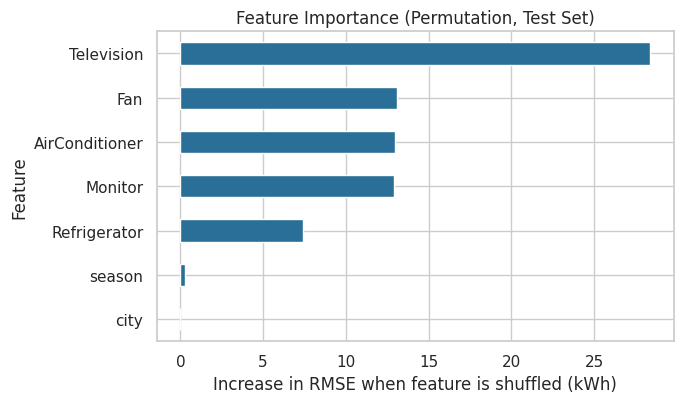

,Feature,"Importance (RMSE increase, kWh)"
5,Television,28.41
2,Fan,13.06
4,AirConditioner,12.99
6,Monitor,12.94
3,Refrigerator,7.39
1,season,0.28
0,city,-0.02


Derived bill (kWh_pred x tariff): {'MAE': 593.958, 'RMSE': 690.789, 'R2': 0.581}


In [ ]:
#CELL 17:(Feature Importance )
pi = permutation_importance(final_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error")
imp = pd.DataFrame({"Feature": FEATURES, "Importance (RMSE increase, kWh)": pi.importances_mean}).sort_values("Importance (RMSE increase, kWh)")
R["feature_importance"] = imp.sort_values("Importance (RMSE increase, kWh)", ascending=False).round(3).to_dict(orient="records")
imp.set_index("Feature").plot.barh(legend=False, figsize=(7, 4.2), color="#2a6f97")
plt.title("Feature Importance (Permutation, Test Set)"); plt.xlabel("Increase in RMSE when feature is shuffled (kWh)"); plt.ylabel("Feature")
plt.tight_layout(); plt.savefig("figures/fig_4_8_feature_importance.png", dpi=200); plt.show()
display(imp.sort_values("Importance (RMSE increase, kWh)", ascending=False).round(2))
# Bill is NOT a second model: bill = predicted kWh x city tariff. We check how accurate this derived value is.
tar_test = X_test["city"].map(TARIFF)
bill_actual = eb.loc[X_test.index, "monthly_bill_inr"]
bill_pred = final_pred * tar_test
R["derived_bill_metrics"] = metrics(bill_actual, bill_pred)
print("Derived bill (kWh_pred x tariff):", {k: round(v, 3) for k, v in R["derived_bill_metrics"].items()})


In [ ]:
#CELL 18:(Save the Final Model)
joblib.dump(final_model, "model/final_energy_model.joblib")
meta = {"final_model": FINAL_NAME, "features": FEATURES, "target": TARGET, "tariff_by_city": TARIFF,
        "cities": sorted(data["city"].unique()), "seasons": sorted(data["season"].unique()),
        "ranges": {f: [float(data[f].min()), float(data[f].max())] for f in NUM},
        "monitor_values": sorted(float(v) for v in data["Monitor"].unique())}
json.dump(meta, open("model/model_metadata.json", "w"), indent=2)
reloaded = joblib.load("model/final_energy_model.joblib")
assert np.allclose(reloaded.predict(X_test), final_pred), "Reloaded model gives different predictions!"
print("Model saved and reloaded successfully (predictions identical).")


Model saved and reloaded successfully (predictions identical).


In [ ]:
#CELL 19:(Sample Predictions and UI Test Cases)
def validate_and_predict(model, city, season, fan, fridge, ac, tv, monitor):
    """Shared by the test cases and the web UI. Returns (ok, message, kwh, bill)."""
    errs = []
    if city not in meta["cities"]: errs.append("Select a valid city.")
    if season not in meta["seasons"]: errs.append("Select a valid season.")
    vals = {"Fan": fan, "Refrigerator": fridge, "AirConditioner": ac, "Television": tv, "Monitor": monitor}
    for k, v in vals.items():
        lo, hi = meta["ranges"][k]
        if v is None or (isinstance(v, float) and np.isnan(v)): errs.append(f"{k}: enter a number.")
        elif not (lo <= v <= hi): errs.append(f"{k}: must be between {lo:g} and {hi:g} (range in the training data).")
    if monitor is not None and monitor not in meta["monitor_values"]: errs.append(f"Monitor: must be one of {meta['monitor_values']}.")
    if errs: return False, " | ".join(errs), None, None
    row = pd.DataFrame([{"city": city, "season": season, **vals}])[FEATURES]
    kwh = float(model.predict(row)[0]); return True, "OK", kwh, kwh * meta["tariff_by_city"][city]

# Three realistic cases taken from the unseen test set (low / median / high consumption).
tc = []
for label, q in [("Low-consumption household", .10), ("Typical household", .50), ("High-consumption household", .90)]:
    idx = (y_test - y_test.quantile(q)).abs().idxmin(); r = X_test.loc[idx]
    ok, msg, kwh, bill = validate_and_predict(final_model, r["city"], r["season"], r["Fan"], r["Refrigerator"], r["AirConditioner"], r["Television"], r["Monitor"])
    actual = float(y_test.loc[idx]); err = kwh - actual
    tol = final_m["RMSE"]
    tc.append({"Test case": label, "Input": f'{r["city"]}, {r["season"]}, Fan={r["Fan"]:g}, Fridge={r["Refrigerator"]:g}, AC={r["AirConditioner"]:g}, TV={r["Television"]:g}, Monitor={r["Monitor"]:g}',
               "Expected (recorded kWh)": round(actual, 1), "Actual (predicted kWh)": round(kwh, 1), "Error": round(err, 1),
               "Status": "Pass" if abs(err) <= tol else "Fail"})
tc_df = pd.DataFrame(tc); display(tc_df)
print(f"Pass rule: absolute error <= test RMSE ({final_m['RMSE']:.1f} kWh).")

# Input-validation tests
bad = [("Fan out of range (50)", ("New Delhi", "Summer", 50.0, 20.0, 1.0, 5.0, 1.0)),
       ("Negative television value", ("New Delhi", "Winter", 10.0, 20.0, 1.0, -3.0, 1.0)),
       ("Invalid city", ("Atlantis", "Winter", 10.0, 20.0, 1.0, 5.0, 1.0))]
vt = []
for label, args in bad:
    ok, msg, _, _ = validate_and_predict(final_model, *args)
    vt.append({"Test case": label, "Expected": "Input rejected", "Actual": "Rejected: " + msg if not ok else "Accepted", "Status": "Pass" if not ok else "Fail"})
vt_df = pd.DataFrame(vt); display(vt_df)
R["ui_test_cases"] = tc; R["ui_validation_tests"] = vt


,Test case,Input,Expected (recorded kWh),Actual (predicted kWh),Error,Status
0,Low-consumption household,"Navi Mumbai, Autumn, Fan=11, Fridge=23, AC=2, ...",355.0,427.5,72.5,Pass
1,Typical household,"Noida, Summer, Fan=16, Fridge=23, AC=0, TV=9, ...",516.0,450.2,-65.8,Pass
2,High-consumption household,"Gurgaon, Monsoon, Fan=13, Fridge=22, AC=3, TV=...",673.0,616.0,-57.0,Pass


Pass rule: absolute error <= test RMSE (82.3 kWh).


,Test case,Expected,Actual,Status
0,Fan out of range (50),Input rejected,Rejected: Fan: must be between 5 and 23 (range...,Pass
1,Negative television value,Input rejected,Rejected: Television: must be between 3 and 22...,Pass
2,Invalid city,Input rejected,Rejected: Select a valid city.,Pass


In [ ]:
#CELL 20:(Web Interface )
# 23a. Export the exact model equation
ui_name = FINAL_NAME if FINAL_NAME in ("Linear Regression", "Ridge Regression") else "Linear Regression"
ui_pipe = fitted[ui_name]
prep, lin = ui_pipe.named_steps["prep"], ui_pipe.named_steps["model"]
coef = dict(zip(prep.get_feature_names_out(), lin.coef_))
scaler = prep.named_transformers_["num"].named_steps["scaler"]
MODEL = {"intercept": float(lin.intercept_), "numeric": {}, "city": {}, "season": {},
         "tariff": {k: float(v) for k, v in TARIFF.items()}}
for i, f in enumerate(NUM):
    MODEL["numeric"][f] = {"mean": float(scaler.mean_[i]), "scale": float(scaler.scale_[i]), "coef": float(coef["num__" + f]),
                           "values": [float(v) for v in sorted(data[f].unique())], "median": float(data[f].median())}
for n, c in coef.items():
    if n.startswith("cat__city_"):   MODEL["city"][n[len("cat__city_"):]] = float(c)
    if n.startswith("cat__season_"): MODEL["season"][n[len("cat__season_"):]] = float(c)
ui_pred = ui_pipe.predict(X_test); ui_m = metrics(y_test, ui_pred)
MODEL["metrics"] = {"mae": ui_m["MAE"], "rmse": ui_m["RMSE"], "r2": ui_m["R2"], "train": int(len(X_train)),
                    "mean": float(y.mean()), "kmin": float(y.min()), "kmax": float(y.max()),
                    "q33": float(y.quantile(1/3)), "q66": float(y.quantile(2/3)), "model": ui_name}

def equation(row):      # exactly what the website computes
    s = MODEL["intercept"]
    for f, d in MODEL["numeric"].items():
        s += d["coef"] * (row[f] - d["mean"]) / d["scale"]
    return s + MODEL["city"][row["city"]] + MODEL["season"][row["season"]]

check = np.array([equation(r) for r in X_test.to_dict("records")])
diff = np.abs(check - ui_pred).max()
print("Model used by the website:", ui_name)
print("Max difference between the website equation and the trained pipeline: %.2e kWh" % diff)
assert diff < 1e-6, "Website equation does not match the pipeline!"

# Why the sliders start at level 0 (= lowest value in the data) and not at literal zero:
lowest = {f: MODEL["numeric"][f]["values"][0] for f in NUM}
zeros = {f: 0 for f in NUM}
base = {"city": sorted(MODEL["city"])[0], "season": "Summer"}
print("\nLowest values that exist in the data:", lowest)
print("Equation at the lowest data values : %.1f kWh (valid, inside the data)" % equation({**base, **lowest}))
print("Equation if every appliance = 0    : %.1f kWh (impossible - the model never saw such households)" % equation({**base, **zeros}))


Model used by the website: Linear Regression
Max difference between the website equation and the trained pipeline: 2.27e-13 kWh

Lowest values that exist in the data: {'Fan': 5.0, 'Refrigerator': 17.0, 'AirConditioner': 0.0, 'Television': 3.0, 'Monitor': 1.0}
Equation at the lowest data values : 236.5 kWh (valid, inside the data)
Equation if every appliance = 0    : -87.6 kWh (impossible - the model never saw such households)


In [ ]:
# CELL 26 — Energy Forecast + Cost Reducer (Flask + ngrok; paste into one Colab cell)
# Run this after the project has trained `final_model` and created `FEATURES`, `TARIFF`, `data`, and `df`.

import importlib.util
import subprocess
import sys
import json
import re
import os
import threading
import getpass
import pandas as pd

_missing_packages = [name for name in ("flask", "pyngrok") if importlib.util.find_spec(name) is None]
if _missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "flask", "pyngrok"])

from flask import Flask, jsonify, make_response, request
from pyngrok import conf, ngrok

# The five appliance features used by the trained household model.
APP_FEATURES = ["Fan", "Refrigerator", "AirConditioner", "Television", "Monitor"]
CITY_CHOICES = sorted(str(x) for x in data["city"].dropna().unique())
SEASON_CHOICES = sorted(str(x) for x in data["season"].dropna().unique())
TARIFF = {str(k): float(v) for k, v in TARIFF.items()}

# Rated wattage values are taken from matching rows in the supplied dataset
# when available. Fallback values keep the planner usable if a source row is absent.
FALLBACK_WATTS = {
    "Fan": 83.0,
    "Refrigerator": 871.5,
    "AirConditioner": 45.0,
    "Television": 54.0,
    "Monitor": 31.5,
}
ALIASES = {
    "Fan": {"fan", "fans"},
    "Refrigerator": {"refrigerator", "fridge"},
    "AirConditioner": {"airconditioner", "air conditioner", "ac"},
    "Television": {"television", "tv"},
    "Monitor": {"monitor", "screen"},
}

def _normalise_appliance(value):
    return re.sub(r"[^a-z0-9]+", " ", str(value).strip().lower()).strip()

APP_WATTS = FALLBACK_WATTS.copy()
if "appliance" in df.columns and "power_watts_max" in df.columns:
    _power_rows = df[["appliance", "power_watts_max"]].copy()
    _power_rows["power_watts_max"] = pd.to_numeric(
        _power_rows["power_watts_max"], errors="coerce"
    )
    _power_rows = _power_rows.dropna(
        subset=["appliance", "power_watts_max"]
    )
    _power_rows = _power_rows[_power_rows["power_watts_max"] > 0]
    _power_rows["_normalised"] = _power_rows["appliance"].map(
        _normalise_appliance
    )

    for _feature, _names in ALIASES.items():
        _match = _power_rows[
            _power_rows["_normalised"].isin(
                {_normalise_appliance(x) for x in _names}
            )
        ]
        if not _match.empty:
            APP_WATTS[_feature] = float(
                _match["power_watts_max"].median()
            )

MAX_REDUCTION = 0.40
APP_DAYS_PER_MONTH = 30

def run_energy_model(payload):
    """Calculate hours-based usage and show the trained model result separately."""
    try:
        if not isinstance(payload, dict):
            return {
                "ok": False,
                "message": "Please enter the household details and try again."
            }

        city = str(payload.get("city", ""))
        season = str(payload.get("season", ""))

        if city not in CITY_CHOICES or season not in SEASON_CHOICES:
            return {
                "ok": False,
                "message": "Choose a valid city and season."
            }

        values = {
            feature: float(payload.get(feature, 0) or 0)
            for feature in APP_FEATURES
        }
        entered_hours_per_day = {
            feature: float(
                payload.get(f"{feature}_hours_per_day", 0) or 0
            )
            for feature in APP_FEATURES
        }

        if any(value < 0 for value in values.values()):
            return {
                "ok": False,
                "message": "Appliance values cannot be negative."
            }

        if any(
            value < 0 or value > 24
            for value in entered_hours_per_day.values()
        ):
            return {
                "ok": False,
                "message": "Daily appliance hours must be between 0 and 24."
            }

        hours_per_day = entered_hours_per_day.copy()

        # If a refrigerator is entered, keep it running 24 hours per day.
        if values["Refrigerator"] > 0:
            hours_per_day["Refrigerator"] = 24.0

        if any(value > 0 for value in values.values()):
            row = pd.DataFrame(
                [{"city": city, "season": season, **values}],
                columns=FEATURES,
            )
            model_reference_kwh = max(
                0.0, float(final_model.predict(row)[0])
            )
        else:
            model_reference_kwh = 0.0

        # The hours-based estimate uses quantity, rated watts, and daily hours.
        # The trained model's count-based estimate is displayed separately because
        # its training data does not include per-appliance usage hours.
        kwh = sum(
            APP_WATTS[feature]
            * values[feature]
            * hours_per_day[feature]
            * APP_DAYS_PER_MONTH
            / 1000
            for feature in APP_FEATURES
        )

        tariff = float(TARIFF.get(city, 0.0))

        return {
            "ok": True,
            "kwh": kwh,
            "bill": kwh * tariff,
            "model_reference_kwh": model_reference_kwh,
            "tariff": tariff,
            "city": city,
            "season": season,
            "message": "Prediction ready.",
        }

    except Exception as exc:
        return {
            "ok": False,
            "message": f"Could not calculate the prediction: {exc}",
        }

APP_DATA = json.dumps({
    "cities": CITY_CHOICES,
    "seasons": SEASON_CHOICES,
    "appliances": APP_FEATURES,
    "watts": APP_WATTS,
    "maxReduction": MAX_REDUCTION,
}, ensure_ascii=False)

APP_HTML = r'''<style>
@import url('https://fonts.googleapis.com/css2?family=DM+Mono:wght@400;500&family=DM+Sans:wght@400;500;600;700&family=Space+Grotesk:wght@400;500;600;700&display=swap');
:root{--ink:#172b26;--muted:#71817a;--paper:#f6f5ef;--white:#fffefa;--green:#c8f169;--deep:#143d32;--line:#e6e8dc;--coral:#ff8067;--blue:#cbe9ee;--shadow:0 24px 65px rgba(23,43,38,.11)}
*{box-sizing:border-box}
html{scroll-behavior:smooth}
body{margin:0;background:var(--paper);color:var(--ink);font-family:'DM Sans',sans-serif;font-size:15px}
button,input,select{font:inherit}
button{cursor:pointer}
.shell{max-width:1280px;margin:auto;padding:20px 26px 60px}
.nav{display:flex;align-items:center;justify-content:space-between;padding:8px 4px 22px}
.brand{display:flex;align-items:center;gap:10px;font:700 20px 'Space Grotesk',sans-serif;letter-spacing:-.7px}
.brand-mark{width:35px;height:35px;border-radius:12px;background:var(--deep);color:var(--green);display:grid;place-items:center;font-size:19px;box-shadow:0 6px 16px #143d3230}
.nav-right{display:flex;align-items:center;gap:18px;color:var(--muted);font-size:13px}
.live{display:flex;align-items:center;gap:8px}
.live i{width:8px;height:8px;border-radius:50%;background:#60b878;box-shadow:0 0 0 5px #60b87822;animation:pulse 1.9s infinite}
.hero{display:grid;grid-template-columns:1.04fr .96fr;min-height:370px;background:var(--deep);color:#f6f8ef;border-radius:29px;overflow:hidden;position:relative;box-shadow:var(--shadow)}
.hero:before{content:'';position:absolute;width:430px;height:430px;background:#c8f16917;border-radius:50%;filter:blur(3px);left:-145px;bottom:-275px}
.hero-copy{padding:47px 34px 42px 48px;position:relative;z-index:2}
.eyebrow{font:500 11px 'DM Mono',monospace;text-transform:uppercase;letter-spacing:1.8px;color:var(--green);display:flex;align-items:center;gap:9px}
.eyebrow:before{content:'';width:18px;height:1px;background:var(--green)}
h1{font:600 clamp(38px,5vw,66px)/.98 'Space Grotesk',sans-serif;letter-spacing:-3.8px;margin:23px 0 17px;max-width:570px}
h1 span{color:var(--green)}
.hero-copy>p{color:#bdcbc1;max-width:450px;line-height:1.65;margin:0}
.hero-actions{display:flex;gap:10px;margin-top:28px;flex-wrap:wrap}
.button{border:0;border-radius:12px;padding:13px 18px;font-weight:700;transition:transform .2s,box-shadow .2s,background .2s}
.button:hover{transform:translateY(-2px);box-shadow:0 10px 25px #0002}
.button-lime{background:var(--green);color:var(--deep)}
.button-glass{background:#ffffff10;color:#f7f9f1;border:1px solid #ffffff27}
.hero-art{position:relative;min-height:330px;display:flex;align-items:center;justify-content:center;overflow:hidden;background:radial-gradient(ellipse at 58% 45%,#34715a 0%,#194b3d 38%,#143d32 75%)}
.hero-art:after{content:'';position:absolute;inset:0;background-image:radial-gradient(#d8f3d71b 1px,transparent 1px);background-size:20px 20px;mask-image:linear-gradient(90deg,transparent,black)}
.orbit{position:absolute;width:320px;height:320px;border:1px solid #dbf4d828;border-radius:50%;animation:spin 36s linear infinite}
.orbit:before,.orbit:after{content:'';position:absolute;border-radius:50%;background:var(--green);box-shadow:0 0 20px #c8f169}
.orbit:before{width:8px;height:8px;top:32px;left:70px}
.orbit:after{width:5px;height:5px;bottom:37px;right:36px;background:#ff896e;box-shadow:0 0 16px #ff896e}
.sun{position:absolute;width:81px;height:81px;background:#d8fb91;border-radius:50%;top:38px;right:14%;filter:drop-shadow(0 0 28px #c8f16966);animation:bob 5s ease-in-out infinite}
.house{position:relative;z-index:1;width:min(92%,440px);filter:drop-shadow(0 23px 20px #061b163c);animation:bob 6s ease-in-out infinite}
.float-chip{position:absolute;z-index:3;padding:11px 14px;border:1px solid #ffffff35;border-radius:13px;background:#163e33c9;backdrop-filter:blur(9px);color:#e6f2df;font:11px 'DM Mono',monospace;box-shadow:0 12px 25px #061b1640}
.chip-a{left:8%;top:23%}
.chip-b{right:7%;bottom:15%}
.chip-a b,.chip-b b{color:var(--green);font-size:15px;display:block;margin-top:4px}
.intro-row{display:flex;align-items:end;justify-content:space-between;gap:20px;margin:39px 2px 18px}
.section-tag{color:#82918a;font:500 10px 'DM Mono',monospace;text-transform:uppercase;letter-spacing:1.5px}
.intro-row h2,.panel-head h2{font:600 27px 'Space Grotesk',sans-serif;letter-spacing:-1px;margin:5px 0 0}
.intro-row p{color:var(--muted);margin:0 0 3px;font-size:13px}
.workspace{display:grid;grid-template-columns:1fr 1fr;gap:18px;align-items:start}
.panel{background:var(--white);border:1px solid #e9e9df;border-radius:22px;padding:23px;box-shadow:0 8px 25px #1c392309;transition:transform .25s,box-shadow .25s}
.panel:hover{box-shadow:0 16px 40px #1c392310}
.panel-head{display:flex;align-items:flex-start;justify-content:space-between;gap:10px;margin-bottom:20px}
.panel-head h2{font-size:21px}
.panel-head p{margin:6px 0 0;color:var(--muted);font-size:12px;line-height:1.5}
.icon-box{width:42px;height:42px;border-radius:14px;display:grid;place-items:center;background:#e9f6d2;color:#35562a;font-size:20px;flex:none}
.step{color:#a2ada3;font:500 10px 'DM Mono',monospace;letter-spacing:1px;margin-top:6px}
.fields{display:grid;grid-template-columns:1fr 1fr;gap:12px}
.field label{display:block;color:#63736a;font:500 11px 'DM Mono',monospace;margin-bottom:7px}
.field input,.field select,.hours-input{width:100%;border:1px solid #e0e4d9;background:#fbfbf6;color:var(--ink);border-radius:10px;padding:12px;outline:none;transition:border .2s,box-shadow .2s}
.field input:focus,.field select:focus,.hours-input:focus{border-color:#8db349;box-shadow:0 0 0 3px #c8f16940}
.appliance-grid{display:grid;grid-template-columns:1fr 1fr;gap:10px;margin-top:16px}
.appliance-input{border:1px solid #e9eae1;border-radius:12px;padding:11px;background:#fff;transition:border .18s,transform .18s}
.appliance-input:focus-within{border-color:#accb6d;transform:translateY(-1px)}
.appliance-input label{display:flex;align-items:center;gap:7px;color:#65756b;font-size:11px;font-weight:600;margin-bottom:7px}
.appliance-input .emoji{font-size:15px}
.appliance-input input{width:100%;border:0;outline:0;background:transparent;font:600 17px 'Space Grotesk',sans-serif;color:var(--ink)}
.hint{font-size:10px;color:#9ba79e;margin-top:3px}
.full{width:100%;margin-top:17px}
.result{min-height:64px;margin-top:15px;border-radius:13px;background:#f4f6ee;padding:14px;color:#758279;font-size:12px;line-height:1.55}
.result-grid{display:grid;grid-template-columns:1fr 1fr;gap:10px}
.result-box{padding:14px;border-radius:13px;background:#eef4e5}
.result-box.dark{background:var(--deep);color:#fff}
.result-label{font:10px 'DM Mono',monospace;text-transform:uppercase;letter-spacing:.6px;opacity:.7}
.result-value{font:600 25px 'Space Grotesk',sans-serif;letter-spacing:-1px;margin-top:6px}
.result-small{font-size:11px;opacity:.68;margin-top:2px}
.divider{height:1px;background:var(--line);margin:17px 0}
.target-row{display:grid;grid-template-columns:1fr 1fr;gap:11px}
.callout{background:#f2f0e5;border:1px solid #e9e5d3;color:#737564;border-radius:11px;padding:11px 12px;font-size:11px;line-height:1.5;margin-top:12px}
.callout strong{color:#46553b}
.rows{display:grid;gap:8px;margin:13px 0}
.usage-row{display:grid;grid-template-columns:minmax(115px,1.2fr) minmax(60px,.5fr) minmax(100px,1fr) 34px;gap:8px;align-items:center}
.usage-row select,.usage-row input{width:100%;min-width:0;border:1px solid #e0e4d9;background:#fff;border-radius:10px;padding:11px;color:var(--ink)}
.usage-row button{height:38px;border:1px solid #f0d9d3;background:#fff8f6;border-radius:9px;color:#c36d5c;transition:background .2s}
.usage-row button:hover{background:#ffe9e2}
.add-row{background:#f4f6ed;color:#50653d;border:1px dashed #c9d5b6;border-radius:10px;padding:10px 13px;font-size:12px;font-weight:700}
.add-row:hover{background:#eaf3d9}
.schedule{width:100%;border-collapse:collapse;margin-top:13px;font-size:11px}
.schedule th{text-align:left;color:#849087;font:10px 'DM Mono',monospace;padding:8px 6px;border-bottom:1px solid var(--line)}
.schedule td{padding:10px 6px;border-bottom:1px solid #eff0e9}
.schedule td:last-child,.schedule th:last-child{text-align:right}
.notice{padding:12px;border-left:3px solid var(--coral);background:#fff4ef;color:#86655d;border-radius:0 10px 10px 0;margin-top:12px;font-size:11px;line-height:1.5}
.status{display:flex;gap:8px;align-items:center;margin-top:11px;font-size:11px;color:var(--muted)}
.status.good{color:#327044}
.status.bad{color:#b45747}
.spinner{display:inline-block;width:14px;height:14px;border:2px solid #c8d2c7;border-top-color:#456e42;border-radius:50%;animation:spin .7s linear infinite}
.footer{display:flex;justify-content:space-between;gap:18px;align-items:center;padding:20px 4px 0;color:#9aa49d;font-size:10px}
.footer strong{color:#738277}
.toast{position:fixed;right:25px;bottom:25px;z-index:50;background:#193e33;color:#f4f8ec;border:1px solid #ffffff20;padding:14px 17px;border-radius:13px;box-shadow:var(--shadow);transform:translateY(18px);opacity:0;pointer-events:none;transition:.3s}
.toast.show{opacity:1;transform:translateY(0)}
@keyframes spin{to{transform:rotate(360deg)}}
@keyframes bob{0%,100%{transform:translateY(0)}50%{transform:translateY(-9px)}}
@keyframes pulse{50%{box-shadow:0 0 0 8px #60b87808;opacity:.65}}
@media(prefers-reduced-motion:reduce){*,*:before,*:after{animation-duration:.01ms!important;animation-iteration-count:1!important;scroll-behavior:auto!important;transition-duration:.01ms!important}}
@media(max-width:850px){.hero{grid-template-columns:1fr}.hero-copy{padding:38px 30px 28px}.hero-art{min-height:265px}.house{width:360px}.workspace{grid-template-columns:1fr}.intro-row{align-items:start;flex-direction:column}.nav-right{gap:9px}.nav-right span:not(.live){display:none}}
@media(max-width:520px){.shell{padding:12px 13px 35px}.hero{border-radius:21px}.hero-copy{padding:30px 23px 24px}h1{font-size:43px;letter-spacing:-2.8px}.hero-art{min-height:220px}.house{width:290px}.sun{width:55px;height:55px;right:10%;top:28px}.orbit{width:240px;height:240px}.float-chip{font-size:9px;padding:8px 10px}.panel{padding:17px;border-radius:17px}.fields,.target-row{grid-template-columns:1fr}.appliance-grid{gap:7px}.appliance-input{padding:9px}.usage-row{grid-template-columns:minmax(0,1.2fr) 54px minmax(0,1fr) 28px;gap:4px}.usage-row select,.usage-row input{padding:9px 6px;font-size:11px}.intro-row h2{font-size:24px}.footer{align-items:flex-start;flex-direction:column}}
</style>
<style>
:root{--ink:#f2efff;--muted:#aaa2c4;--paper:#100d20;--white:#1a162b;--green:#83e9e1;--deep:#19152b;--line:#342c49;--coral:#ff9eae;--blue:#bd9dff;--shadow:0 24px 70px #05030c70}
body{background:#100d20;color:#f2efff}
.shell{max-width:1280px;color:#f2efff}
.nav{border-bottom:1px solid #332d4b}
.brand-mark{background:#bd9dff;color:#1b1430}
.nav-right{color:#b9b1d2}
.live i{background:#83e9e1;box-shadow:0 0 0 5px #83e9e122}
.hero{background:linear-gradient(115deg,#19152b 0%,#231b3d 58%,#19152b 100%);border:1px solid #3c3157;box-shadow:0 20px 60px #05030c88}
.hero:before{background:#8e72e922;filter:blur(18px)}
.eyebrow{color:#83e9e1}
.eyebrow:before{background:#83e9e1}
h1 span{color:#83e9e1}
.hero-copy>p{color:#c0b9d5}
.hero-art{background:radial-gradient(ellipse at 58% 45%,#493271 0%,#231b3d 42%,#100d20 84%)}
.hero-art:after{background-image:radial-gradient(#d7cfff2b 1px,transparent 1px);mask-image:linear-gradient(90deg,transparent,black)}
.orbit{border-color:#d7cfff30}
.orbit:before,.orbit:after{background:#83e9e1;box-shadow:0 0 22px #83e9e1}
.orbit:after{background:#bd9dff;box-shadow:0 0 18px #bd9dff}
.sun{width:142px;height:142px;top:calc(50% - 71px);right:calc(50% - 71px);background:radial-gradient(circle at 35% 33%,#a7f5ed 0 6%,#8275e7 19%,#40316a 48%,#151024 70%);box-shadow:0 0 0 11px #bd9dff12,0 0 42px #9380ff75;filter:none;animation:bob 5s ease-in-out infinite}
.house{display:none}
.float-chip{background:#1b1730dc;border-color:#8c7ebc55;color:#e9e3fa;box-shadow:0 14px 32px #08061175}
.chip-a b,.chip-b b{color:#83e9e1}
.button-lime{background:#83e9e1;color:#152127}
.button-glass{background:#ffffff0a;color:#f2efff;border-color:#ffffff2a}
.intro-row .section-tag{color:#83e9e1}
.intro-row p{color:#aaa2c4}
.panel{background:#1a162b;border-color:#342c49;box-shadow:0 10px 34px #05030c55}
.panel:hover{box-shadow:0 16px 42px #05030c88}
.panel-head p{color:#aaa2c4}
.step{color:#8d85aa}
.icon-box{background:#2b2443;color:#83e9e1}
.field label{color:#c5bdd9}
.field input,.field select,.hours-input,.quantity-input,.usage-row select,.usage-row input{background:#110e20;color:#eee9ff;border-color:#3c3453}
.field input:focus,.field select:focus,.hours-input:focus{border-color:#83e9e1;box-shadow:0 0 0 3px #83e9e122}
.appliance-input{background:#141125;border-color:#2c2640}
.appliance-input:focus-within{border-color:#83e9e1}
.appliance-input label{color:#c5bdd9}
.appliance-input .appliance-title{display:flex;align-items:center;gap:7px;margin-bottom:7px;color:#c5bdd9;font-size:11px;font-weight:600}
.appliance-input input{color:#f2efff}
.appliance-values{display:grid;grid-template-columns:1fr 1fr;gap:8px}
.appliance-values .value-field label{display:block;margin:0 0 4px;font-size:9px;letter-spacing:.5px}
.appliance-values .value-field input{width:100%;padding:8px;border:1px solid #3c3453;border-radius:8px;background:#110e20;font:600 14px 'Space Grotesk',sans-serif}
.appliance-values .value-field input:focus{border-color:#83e9e1;box-shadow:0 0 0 3px #83e9e122}
.hint{color:#aaa2c4}
.result-grid{grid-template-columns:repeat(auto-fit,minmax(170px,1fr))}
.result{background:#141125;color:#aaa2c4}
.result-box{background:#28213e;color:#f2efff}
.result-box.dark{background:#83e9e1;color:#152127}
.divider{background:#342c49}
.callout{background:#201a35;border-color:#3d3357;color:#c4bbd9}
.callout strong{color:#83e9e1}
.usage-row button{background:#392335;color:#ff9eae;border-color:#593246}
.usage-row button:hover{background:#4a2a3b}
.usage-row button:disabled{opacity:.35;cursor:not-allowed}
.add-row{background:#201a35;color:#83e9e1;border-color:#62558d}
.add-row:hover{background:#292142}
.schedule th{color:#aaa2c4;border-color:#342c49}
.schedule td{border-color:#2c2640}
.notice{background:#2a1b30;color:#d6b9ce;border-color:#ff9eae}
.status{color:#aaa2c4}
.status.good{color:#83e9e1}
.status.bad{color:#ff9eae}
.spinner{border-color:#564c72;border-top-color:#83e9e1}
.footer{color:#8d85aa}
.footer strong{color:#d7cfff}
.toast{background:#211a37;color:#f2efff;border-color:#65558a}
.hero-art .chip-a{left:7%;top:20%}
.hero-art .chip-b{right:7%;bottom:17%}
@media(max-width:850px){.hero-art{min-height:265px}.sun{width:116px;height:116px;top:calc(50% - 58px);right:calc(50% - 58px)}}
@media(max-width:520px){.sun{width:88px;height:88px;top:calc(50% - 44px);right:calc(50% - 44px)}.hero-art .chip-a{left:4%;top:12%}.hero-art .chip-b{right:4%;bottom:10%}}
@media(max-width:520px){.appliance-grid{grid-template-columns:1fr}}
</style>
<div class="shell">
  <nav class="nav"><div class="brand"><div class="brand-mark">✦</div>WattWise / Eclipse</div><div class="nav-right"><span class="live"><i></i> Connected</span><span>Monthly energy planner</span></div></nav>
  <header class="hero">
    <div class="hero-copy"><div class="eyebrow">Light up your next decision</div><h1>Forecast first.<br><span>Then fine-tune.</span></h1><p>Get your household prediction, then shape a realistic appliance schedule around your monthly bill target.</p><div class="hero-actions"><button class="button button-lime" onclick="document.querySelector('#forecast').scrollIntoView({behavior:'smooth'})">01&nbsp; Run forecast&nbsp; ↘</button><button class="button button-glass" onclick="document.querySelector('#reducer').scrollIntoView({behavior:'smooth'})">02&nbsp; Plan usage</button></div></div>
    <div class="hero-art" aria-label="Glowing solar eclipse illustration"><div class="orbit"></div><div class="sun"></div>
      <div class="float-chip chip-a">YOUR MONTHLY OUTLOOK<b>Forecast first</b></div><div class="float-chip chip-b">REALISTIC TARGETS<b>Adjust with confidence</b></div>
      <svg class="house" viewBox="0 0 500 360" role="img" aria-label="A modern home with solar panels">
        <defs><linearGradient id="wall" x1="0" x2="1" y1="0" y2="1"><stop stop-color="#f8f4df"/><stop offset="1" stop-color="#d8dfc3"/></linearGradient><linearGradient id="roof" x1="0" x2="1"><stop stop-color="#a8db69"/><stop offset="1" stop-color="#6dbb73"/></linearGradient><linearGradient id="glass" x1="0" x2="1"><stop stop-color="#a8d8d0"/><stop offset="1" stop-color="#579b8a"/></linearGradient></defs>
        <ellipse cx="253" cy="322" rx="180" ry="20" fill="#061b16" opacity=".25"/><path d="M102 172 250 66l148 106v139H102z" fill="url(#wall)"/><path d="m74 176 176-126 177 126-17 24L250 91 91 200z" fill="#183d32"/><path d="m118 168 129-91 131 91-11 12-120-83-119 83z" fill="url(#roof)"/><path d="M178 123 239 80l58 40-60 43z" fill="#234f49"/><path d="m187 123 52-37v13l-52 38zM217 143l54-38v12l-54 39z" fill="#9bd6d0" opacity=".9"/><path d="M175 202h67v109h-67z" fill="#b7d2c6"/><path d="M183 211h51v91h-51z" fill="url(#glass)"/><path d="M255 205h48v56h-48z" fill="#f3b970"/><path d="M263 213h32v40h-32z" fill="#f9da98"/><path d="M318 205h48v56h-48z" fill="#f3b970"/><path d="M326 213h32v40h-32z" fill="#f9da98"/><path d="M266 269h40v42h-40z" fill="#bd7955"/><path d="M287 269v42" stroke="#e7bd87" stroke-width="2"/><path d="M119 277c-28-21-30-59-8-82 3 31 20 45 36 50 5 15-7 29-28 32zM386 286c28-21 30-59 8-82-3 31-20 45-36 50-5 15 7 29 28 32z" fill="#78af68"/><path d="M91 310h324" stroke="#b5d879" stroke-width="5" stroke-linecap="round"/><circle cx="138" cy="278" r="10" fill="#ff9e73"/><circle cx="376" cy="287" r="8" fill="#f2d86e"/>
      </svg>
    </div>
  </header>
  <div class="intro-row"><div><div class="section-tag">WattWise / 02</div><h2>Your monthly outlook</h2></div><p>Predict household use, then fine-tune a practical schedule.</p></div>
  <main class="workspace">
    <section class="panel" id="forecast"><div class="panel-head"><div><div class="step">01 / FORECAST</div><h2>Household snapshot</h2><p>Enter appliance quantities and average daily hours. The bill uses rated watts, 30 days of use, and your city tariff.</p></div><div class="icon-box">⌂</div></div>
      <div class="fields"><div class="field"><label for="city">CITY</label><select id="city"></select></div><div class="field"><label for="season">SEASON</label><select id="season"></select></div></div>
      <div id="applianceInputs" class="appliance-grid"></div>
      <button id="predictBtn" class="button button-lime full">Show my energy forecast&nbsp; →</button>
      <div id="predictionResult" class="result" aria-live="polite">Your forecast will appear here. With no appliance values entered, the estimate is ₹0.</div>
      <div id="predictionStatus" class="status"></div>
    </section>
    <section class="panel" id="reducer"><div class="panel-head"><div><div class="step">02 / COST REDUCER</div><h2>Shape your monthly plan</h2><p>Starts with the quantities and daily hours from Household Snapshot. Adjust the quantity or monthly hours before calculating.</p></div><div class="icon-box">↘</div></div>
      <div class="target-row"><div class="field"><label for="targetBill">YOUR TARGET BILL (₹ / MONTH)</label><input id="targetBill" type="number" min="0" step="any" placeholder="Run forecast first"></div><div class="field"><label for="planCity">TARIFF CITY</label><select id="planCity"></select></div></div>
      <div class="callout">The refrigerator stays at <strong>24 hours/day</strong>. Other appliances are adjusted first. The target cannot be more than 40% below the household estimate or below the refrigerator's minimum estimated cost.</div>
      <div class="divider"></div><div class="field"><label>APPLIANCE SCHEDULE · QUANTITY AND HOURS PER MONTH</label></div>
      <div id="usageRows" class="rows"></div><button id="addRow" class="add-row">＋ Add appliance row</button>
      <button id="planBtn" class="button button-lime full">Find my suggested schedule&nbsp; →</button>
      <div id="planResult" class="result" aria-live="polite">Run the forecast, set a target, and add appliance hours to see a suggested schedule.</div>
      <div id="planStatus" class="status"></div>
    </section>
  </main>
  <footer class="footer"><span><strong>WattWise / Eclipse</strong> · Household energy planning</span><span>Bill estimates use appliance quantities, daily hours, dataset wattage and city tariff. The trained-model reference is shown separately.</span></footer>
</div><div id="toast" class="toast" role="status"></div>'''

APP_JS = r'''(() => {
  const cfg = __APP_DATA__;
  const $ = (s) => document.querySelector(s);
  const money = (x) => new Intl.NumberFormat('en-IN',{style:'currency',currency:'INR',maximumFractionDigits:0}).format(Number(x)||0);
  const number = (x,d=1) => new Intl.NumberFormat('en-IN',{maximumFractionDigits:d}).format(Number(x)||0);
  const safe = (x) => String(x).replace(/[&<>"']/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));
  const setStatus = (id,text,kind='') => { const n=$('#'+id); n.className='status '+kind; n.innerHTML=text; };
  const toast = (message) => { const n=$('#toast'); n.textContent=message; n.classList.add('show'); setTimeout(()=>n.classList.remove('show'),2400); };
  const title = (name) => name==='AirConditioner' ? 'Air conditioner' : name;
  const icons = {Fan:'✳',Refrigerator:'▣',AirConditioner:'❄',Television:'▰',Monitor:'▣'};
  const city=$('#city'), season=$('#season'), planCity=$('#planCity');
  cfg.cities.forEach(x=>{city.add(new Option(x,x));planCity.add(new Option(x,x));});
  cfg.seasons.forEach(x=>season.add(new Option(x,x)));
  const applianceInputs=$('#applianceInputs');
  cfg.appliances.forEach((name,i)=>{
    const box=document.createElement('div'); box.className='appliance-input';
    const isFridge=name==='Refrigerator';
    const hoursAttributes=isFridge?'min="24" max="24" value="24" readonly':'min="0" max="24" step="0.5" placeholder="0"';
    box.innerHTML=`<div class="appliance-title"><span class="emoji">${icons[name]||'◉'}</span>${safe(title(name))}</div><div class="appliance-values"><div class="value-field"><label for="count-${i}">QUANTITY</label><input id="count-${i}" type="number" min="0" step="1" placeholder="0"></div><div class="value-field"><label for="hours-${i}">${isFridge?'HOURS / DAY · FIXED':'HOURS / DAY'}</label><input id="hours-${i}" type="number" ${hoursAttributes}></div></div>${isFridge?'<div class="hint">Kept running all day</div>':''}`;
    applianceInputs.append(box);
  });

  const usageRows=$('#usageRows');

  function addUsageRow(name='',quantity=1,hours=''){
    const row=document.createElement('div');
    row.className='usage-row';

    const options=cfg.appliances.map(x=>
      `<option value="${safe(x)}" ${x===name?'selected':''}>${safe(title(x))}</option>`
    ).join('');

    const isFridge=name==='Refrigerator';
    const rowQuantity=isFridge?Math.max(1,Number(quantity)||1):quantity;
    const rowHours=isFridge?'720':hours;

    row.innerHTML=`<select aria-label="Appliance" ${isFridge?'disabled':''}><option value="">Choose appliance</option>${options}</select><input class="quantity-input" type="number" min="${isFridge?'1':'0'}" step="1" value="${safe(rowQuantity)}" aria-label="Appliance quantity" title="Quantity"><input class="hours-input" type="number" min="${isFridge?'720':'0'}" ${isFridge?'max="720" readonly':''} step="any" placeholder="Hours / month per appliance" value="${safe(rowHours)}" aria-label="Hours per month per appliance" title="Hours per month per appliance"><button type="button" aria-label="Remove row" ${isFridge?'disabled title="Keep the refrigerator in the schedule"':''}>×</button>`;

    const applianceSelect=row.querySelector('select');
    const quantityInput=row.querySelector('.quantity-input');
    const hoursInput=row.querySelector('.hours-input');
    const removeButton=row.querySelector('button');

    applianceSelect.addEventListener('change',()=>{
      const selectedFridge=applianceSelect.value==='Refrigerator';
      quantityInput.min=selectedFridge?'1':'0';

      if(selectedFridge){
        applianceSelect.disabled=true;
        quantityInput.value=Math.max(1,Number(quantityInput.value)||1);
        hoursInput.min='720';
        hoursInput.max='720';
        hoursInput.value='720';
        hoursInput.readOnly=true;
        removeButton.disabled=true;
        removeButton.title='Keep the refrigerator in the schedule';
      }else{
        hoursInput.min='0';
        hoursInput.removeAttribute('max');
        hoursInput.readOnly=false;
        if(hoursInput.value==='720')hoursInput.value='';
        removeButton.disabled=false;
        removeButton.removeAttribute('title');
      }
    });

    removeButton.onclick=()=>{
      if(usageRows.children.length>1){
        row.remove();
      }else{
        applianceSelect.value='';
        quantityInput.min='0';
        quantityInput.value='1';
        hoursInput.min='0';
        hoursInput.removeAttribute('max');
        hoursInput.readOnly=false;
        hoursInput.value='';
        removeButton.disabled=false;
        removeButton.removeAttribute('title');
      }
    };

    usageRows.append(row);
  }

  function loadSnapshotIntoReducer(snapshot){
    usageRows.replaceChildren();
    const selected=snapshot.filter(item=>item.quantity>0);

    if(!selected.length){
      addUsageRow();
      return;
    }

    selected.forEach(item=>
      addUsageRow(item.name,item.quantity,(item.hoursPerDay*30).toFixed(1))
    );
  }

  addUsageRow();
  $('#addRow').onclick=()=>addUsageRow();

  let predicted=null;

  $('#predictBtn').onclick=async()=>{
    const button=$('#predictBtn');
    button.disabled=true;
    button.innerHTML='<span class="spinner"></span> Calculating your outlook…';
    setStatus(
      'predictionStatus',
      'Calculating from appliance quantities, daily hours, wattage and city tariff…'
    );

    try{
      const payload={city:city.value,season:season.value};

      cfg.appliances.forEach((name,i)=>{
        payload[name]=Number($('#count-'+i).value)||0;
        payload[`${name}_hours_per_day`]=Number($('#hours-'+i).value)||0;
      });

      const response=await fetch('/api/predict',{
        method:'POST',
        headers:{'Content-Type':'application/json'},
        body:JSON.stringify(payload)
      });
      const result=await response.json();

      if(!result.ok){
        throw new Error(result.message||'Prediction could not be calculated.');
      }

      const snapshot=cfg.appliances.map((name,i)=>({
        name,
        quantity:Number($('#count-'+i).value)||0,
        hoursPerDay:Number($('#hours-'+i).value)||0
      }));

      predicted=result;
      loadSnapshotIntoReducer(snapshot);

      $('#predictionResult').innerHTML=
        `<div class="result-grid">
          <div class="result-box">
            <div class="result-label">HOURS-BASED MONTHLY USE</div>
            <div class="result-value">${number(result.kwh)} <span style="font-size:13px">kWh</span></div>
            <div class="result-small">Quantity × rated watts × hours/day × 30 ÷ 1,000</div>
          </div>
          <div class="result-box dark">
            <div class="result-label">ESTIMATED BILL</div>
            <div class="result-value">${money(result.bill)}</div>
            <div class="result-small">At ${money(result.tariff)} per kWh · ${safe(result.city)}</div>
          </div>
          <div class="result-box">
            <div class="result-label">TRAINED-MODEL REFERENCE</div>
            <div class="result-value">${number(result.model_reference_kwh)} <span style="font-size:13px">kWh</span></div>
            <div class="result-small">Reference estimate from appliance quantities</div>
          </div>
        </div>`;

      if(!$('#targetBill').value){
        $('#targetBill').value=Number(result.bill).toFixed(0);
      }

      planCity.value=result.city;
      setStatus('predictionStatus','Forecast ready. Set your target and build a schedule.','good');
      toast('Your monthly energy forecast is ready.');
    }catch(e){
      setStatus('predictionStatus',safe(e.message||String(e)),'bad');
    }finally{
      button.disabled=false;
      button.textContent='Show my energy forecast →';
    }
  };

  $('#planBtn').onclick=()=>{
    if(!predicted){
      setStatus(
        'planStatus',
        'Run your household forecast first so the target has a prediction to compare with.',
        'bad'
      );
      $('#forecast').scrollIntoView({behavior:'smooth',block:'center'});
      return;
    }

    const target=Number($('#targetBill').value);
    if(!Number.isFinite(target)||target<0){
      setStatus('planStatus','Enter a target bill of ₹0 or more.','bad');
      return;
    }

    const tariff=Number(cfgTariff(planCity.value));

    // Refrigerator rows always stay at 720 hours per month.
    const items=[...usageRows.children].map(row=>{
      const name=row.querySelector('select').value;
      const refrigerator=name==='Refrigerator';

      return {
        name,
        quantity:refrigerator
          ? Math.max(1,Number(row.querySelector('.quantity-input').value)||1)
          : Math.max(0,Number(row.querySelector('.quantity-input').value)||0),
        hours:refrigerator
          ? 720
          : Math.max(0,Number(row.querySelector('.hours-input').value)||0)
      };
    }).filter(x=>x.name&&x.quantity>0&&x.hours>0);

    if(!items.length){
      $('#planResult').innerHTML=
        `<div class="result-grid">
          <div class="result-box">
            <div class="result-label">ESTIMATED USE</div>
            <div class="result-value">0 <span style="font-size:13px">kWh</span></div>
          </div>
          <div class="result-box dark">
            <div class="result-label">APPLIANCE COST</div>
            <div class="result-value">${money(0)}</div>
          </div>
        </div>
        <div class="callout">No appliance hours were entered, so the appliance schedule cost is <strong>₹0</strong>. Add hours to receive a suggested schedule.</div>`;

      setStatus(
        'planStatus',
        'Your empty schedule costs ₹0. Add any of the five listed appliances to plan hours.',
        'good'
      );
      return;
    }

    const rawCost=items.reduce(
      (sum,x)=>sum+(Number(cfg.watts[x.name]||0)*x.quantity*x.hours/1000*tariff),
      0
    );

    const fixedFridgeCost=items
      .filter(x=>x.name==='Refrigerator')
      .reduce(
        (sum,x)=>sum+(Number(cfg.watts[x.name]||0)*x.quantity*720/1000*tariff),
        0
      );

    const flexibleCost=items
      .filter(x=>x.name!=='Refrigerator')
      .reduce(
        (sum,x)=>sum+(Number(cfg.watts[x.name]||0)*x.quantity*x.hours/1000*tariff),
        0
      );

    const realisticFloor=predicted.bill*(1-cfg.maxReduction);
    const minimumTarget=Math.max(realisticFloor,fixedFridgeCost);

    if(target+0.005<minimumTarget){
      const reason=fixedFridgeCost>realisticFloor
        ? 'The refrigerator stays on for 24 hours/day, so its estimated minimum cost is '
        : 'The lowest realistic target is ';

      $('#planResult').innerHTML=
        `<div class="result-box" style="background:#3b2337">
          <div class="result-label">TARGET TOO LOW</div>
          <div class="result-value" style="color:#ff9eae">${money(target)}</div>
          <div class="result-small">${reason}${money(minimumTarget)}. Raise the target to continue.</div>
        </div>`;

      setStatus(
        'planStatus',
        'This target is below the household plan’s minimum estimated cost.',
        'bad'
      );
      return;
    }

    const flexibleBudget=Math.max(0,target-fixedFridgeCost);
    const factor=flexibleCost>0
      ? Math.min(1,flexibleBudget/flexibleCost)
      : 1;

    const finalCost=fixedFridgeCost+flexibleCost*factor;

    const finalKwh=items.reduce((sum,x)=>{
      const suggestedHours=x.name==='Refrigerator'
        ? 720
        : x.hours*factor;
      return sum+(Number(cfg.watts[x.name]||0)*x.quantity*suggestedHours/1000);
    },0);

    const body=items.map(x=>{
      const suggestedHours=x.name==='Refrigerator'
        ? 720
        : x.hours*factor;
      const kwh=Number(cfg.watts[x.name]||0)*x.quantity*suggestedHours/1000;
      const cost=kwh*tariff;

      return `<tr>
        <td>${safe(title(x.name))}</td>
        <td>${number(x.quantity,0)}</td>
        <td>${number(suggestedHours)}</td>
        <td>${number(kwh,2)} kWh</td>
        <td>${money(cost)}</td>
      </tr>`;
    }).join('');

    const within=rawCost<=target+0.005;

    $('#planResult').innerHTML=
      `<div class="result-grid">
        <div class="result-box">
          <div class="result-label">SCHEDULE ENERGY</div>
          <div class="result-value">${number(finalKwh)} <span style="font-size:13px">kWh</span></div>
          <div class="result-small">Refrigerator remains at 720 hours/month</div>
        </div>
        <div class="result-box dark">
          <div class="result-label">SUGGESTED COST</div>
          <div class="result-value">${money(finalCost)}</div>
          <div class="result-small">Entered schedule: ${money(rawCost)}</div>
        </div>
      </div>
      <div style="overflow:auto">
        <table class="schedule">
          <thead>
            <tr>
              <th>APPLIANCE</th>
              <th>QUANTITY</th>
              <th>HOURS / MO. EACH</th>
              <th>ENERGY</th>
              <th>COST</th>
            </tr>
          </thead>
          <tbody>${body}</tbody>
        </table>
      </div>`;

    setStatus(
      'planStatus',
      within
        ? 'Your entered schedule is within the target bill.'
        : 'Other appliance hours were adjusted; refrigerator use remains fixed at 24 hours/day.',
      within?'good':''
    );
  };

  function cfgTariff(cityName){
    return cfg.tariffs[cityName]||0;
  }

  $('#city').addEventListener('change',()=>{
    if(!predicted)planCity.value=city.value;
  });

  city.addEventListener('change',()=>{
    if(!predicted)planCity.value=city.value;
  });
})();'''

# Add tariff values for the browser-side appliance cost calculation.
APP_DATA = json.dumps({
    "cities": CITY_CHOICES,
    "seasons": SEASON_CHOICES,
    "appliances": APP_FEATURES,
    "watts": APP_WATTS,
    "tariffs": TARIFF,
    "maxReduction": MAX_REDUCTION,
}, ensure_ascii=False)

APP_DATA = APP_DATA.replace("</", "<\\/")
APP_JS = APP_JS.replace("__APP_DATA__", APP_DATA)

flask_app = Flask("wattwise_energy_planner")

FULL_PAGE = """<!doctype html>
<html lang="en">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width,initial-scale=1">
  <title>WattWise — Solar Eclipse energy planner</title>
</head>
<body>""" + APP_HTML + "<script>" + APP_JS + "</script></body></html>"

@flask_app.get("/")
def home_page():
    return make_response(
        FULL_PAGE,
        200,
        {"Content-Type": "text/html; charset=utf-8"},
    )

@flask_app.post("/api/predict")
def predict_api():
    payload = request.get_json(silent=True) or {}
    return jsonify(run_energy_model(payload))

# Read the token from a Colab secret or environment variable first.
# It is never printed or embedded in the website code.
NGROK_AUTHTOKEN = os.environ.get("NGROK_AUTHTOKEN", "").strip()

if not NGROK_AUTHTOKEN:
    try:
        from google.colab import userdata
        NGROK_AUTHTOKEN = (userdata.get("NGROK_AUTHTOKEN") or "").strip()
    except Exception:
        pass

if not NGROK_AUTHTOKEN:
    NGROK_AUTHTOKEN = getpass.getpass(
        "Enter your ngrok authtoken (hidden): "
    ).strip()

if not NGROK_AUTHTOKEN:
    raise ValueError(
        "An ngrok authtoken is required to create the public website link."
    )

# Shut down earlier copies if this cell is run again in the same runtime.
try:
    if "WATTWISE_SERVER" in globals():
        WATTWISE_SERVER.shutdown()
except Exception:
    pass

try:
    if "WATTWISE_TUNNEL" in globals():
        ngrok.disconnect(WATTWISE_TUNNEL.public_url)
except Exception:
    pass

from werkzeug.serving import make_server

WATTWISE_SERVER = make_server("0.0.0.0", 0, flask_app)
WATTWISE_PORT = WATTWISE_SERVER.server_port
WATTWISE_THREAD = threading.Thread(
    target=WATTWISE_SERVER.serve_forever,
    daemon=True,
)
WATTWISE_THREAD.start()

WATTWISE_NGROK_CONFIG = conf.PyngrokConfig(
    auth_token=NGROK_AUTHTOKEN
)

WATTWISE_TUNNEL = ngrok.connect(
    addr=str(WATTWISE_PORT),
    proto="http",
    pyngrok_config=WATTWISE_NGROK_CONFIG,
)

WATTWISE_URL = WATTWISE_TUNNEL.public_url
print("WattWise is ready. Open this public website link:")
print(WATTWISE_URL)

try:
    from IPython.display import HTML, display
    display(HTML(
        f'<a href="{WATTWISE_URL}" target="_blank" rel="noopener">'
        "Open WattWise website</a>"
    ))
except Exception:
    pass

In [ ]:
# Github Connection (DO NOT REMOVE)

import zipfile

with zipfile.ZipFile("wattwise_files.zip", "w") as z:
    z.write("model/final_energy_model.joblib")
    z.write("model/model_metadata.json")
    z.write("/content/master_household_energy_dataset_with_hours final dataset.csv",
            "dataset/master_household_energy_dataset.csv")

from google.colab import files
files.download("wattwise_files.zip")

In [ ]:
import joblib
print(joblib.__version__)